# Notebook 03: Indivisibility — Where Quantum Processes Live

**Goal:** Construct a process that fails the divisibility test and understand
exactly why — negative entries in the intermediate matrix.

By the end of this notebook you will be able to:
- Construct an indivisible stochastic process from a qubit unitary
- Identify which failure mode is triggered and at which times
- Compute the indivisibility signature and interpret its value

In [1]:
import sys
import os
sys.path.insert(0, os.path.abspath('..'))
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from isp.quantum import make_qubit_sigmax_process
from isp.divisibility import check_divisibility, indivisibility_signature
from isp.visualization import plot_transition_matrix

## 1. A Process From Quantum Mechanics

Consider a qubit evolving under $H = \frac{\omega}{2}\sigma_x$.
The unitary is:
$$U(dt) = e^{-iH\,dt} = \begin{pmatrix} \cos\tfrac{\omega\,dt}{2} & -i\sin\tfrac{\omega\,dt}{2} \\ -i\sin\tfrac{\omega\,dt}{2} & \cos\tfrac{\omega\,dt}{2} \end{pmatrix}$$

The stochastic transition matrix takes $|U_{ij}|^2$:
$$T(dt) = \begin{pmatrix} \cos^2\tfrac{\omega\,dt}{2} & \sin^2\tfrac{\omega\,dt}{2} \\ \sin^2\tfrac{\omega\,dt}{2} & \cos^2\tfrac{\omega\,dt}{2} \end{pmatrix}$$

Each column sums to 1. All entries are non-negative. Looks perfectly classical — or does it?

In [2]:
omega = 1.0

# Specific times chosen to expose indivisibility
t1, t2, t3 = 0.0, 3 * np.pi / 4, 5 * np.pi / 6

proc = make_qubit_sigmax_process(omega=omega, times=[t1, t2, t3])

print("Step transition matrices:")
print(f"\nT(t1→t2), dt={t2-t1:.4f}:")
print(proc.transitions[0].round(4))
print(f"\nT(t2→t3), dt={t3-t2:.4f}:")
print(proc.transitions[1].round(4))

Step transition matrices:

T(t1→t2), dt=2.3562:
[[0.1464 0.8536]
 [0.8536 0.1464]]

T(t2→t3), dt=0.2618:
[[ 1.1124 -0.1124]
 [-0.1124  1.1124]]


In [3]:
result = check_divisibility(proc)
print(f"Divisible: {result['divisible']}")
print(f"Failure mode: {result['failure_mode']}")
print(f"At times: {tuple(f'{t:.4f}' for t in result['at_times'])}")
print(f"Message: {result['message']}")

Divisible: False
Failure mode: negative_entries
At times: ('0.0000', '2.3562', '2.6180')
Message: Intermediate matrix T(2.6179938779914944,2.356194490192345) has negative entries: min=-0.112372


In [4]:
# Compute the offending intermediate matrix by hand
T_13 = proc.transition_from_to(0, 2)   # composite T(t1→t3)
T_12 = proc.transition_from_to(0, 1)   # step T(t1→t2)

T_23_candidate = T_13 @ np.linalg.inv(T_12)

print("T(t2→t3) candidate:")
print(T_23_candidate.round(4))
print(f"\nMinimum entry: {T_23_candidate.min():.6f}  ← NEGATIVE")
print(f"Column sums: {T_23_candidate.sum(axis=0).round(6)}")

T(t2→t3) candidate:
[[ 1.1124 -0.1124]
 [-0.1124  1.1124]]

Minimum entry: -0.112372  ← NEGATIVE
Column sums: [1. 1.]


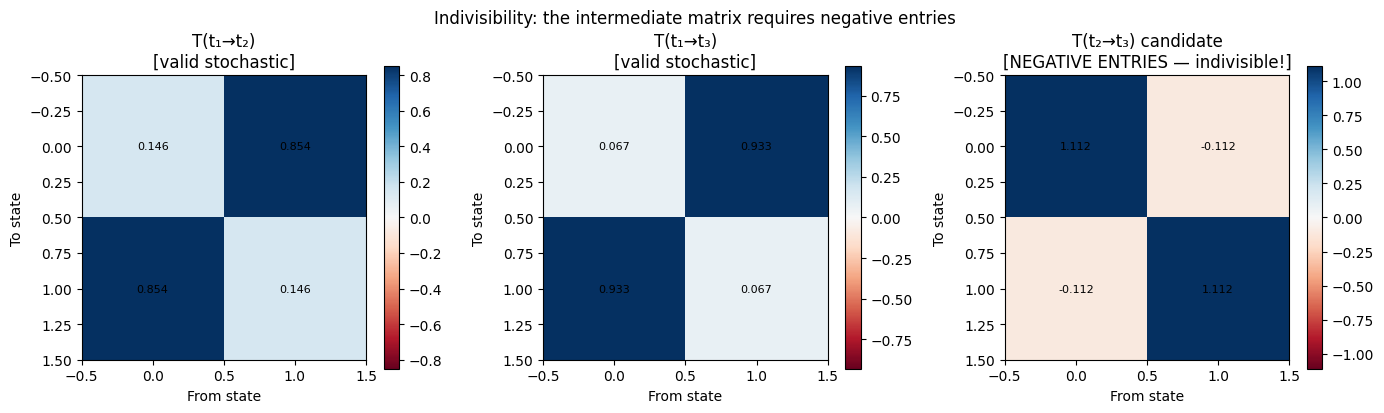

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

plot_transition_matrix(T_12, title="T(t₁→t₂)\n[valid stochastic]", ax=axes[0])
plot_transition_matrix(T_13, title="T(t₁→t₃)\n[valid stochastic]", ax=axes[1])
plot_transition_matrix(T_23_candidate,
                       title="T(t₂→t₃) candidate\n[NEGATIVE ENTRIES — indivisible!]",
                       ax=axes[2])

plt.suptitle("Indivisibility: the intermediate matrix requires negative entries")
plt.tight_layout()
plt.show()

## 2. The Indivisibility Signature

The indivisibility signature measures *how far* a process is from divisible.
It's the magnitude of the most negative entry found across all candidate
intermediate matrices. Zero means classical; positive means quantum territory.

In [6]:
from isp.stochastic import make_markov_chain

L = np.array([[-0.5,  0.3], [0.5, -0.3]])
markov = make_markov_chain(2, L, times=[0.0, 3*np.pi/4, 5*np.pi/6])
quantum = make_qubit_sigmax_process(omega=1.0, times=[0.0, 3*np.pi/4, 5*np.pi/6])

sig_markov  = indivisibility_signature(markov)
sig_quantum = indivisibility_signature(quantum)

print(f"Markov chain signature:  {sig_markov:.6f}  (classical → ~0)")
print(f"Qubit sigma_x signature: {sig_quantum:.6f}  (quantum  → > 0)")

Markov chain signature:  0.000000  (classical → ~0)
Qubit sigma_x signature: 0.112372  (quantum  → > 0)


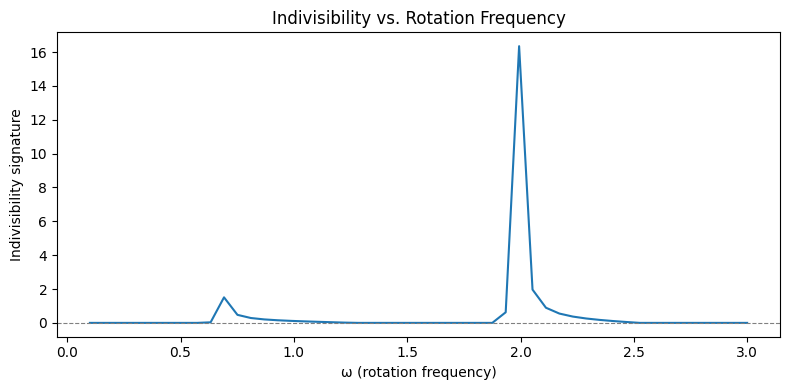

In [7]:
# Sweep omega and time to see how the signature varies
omegas = np.linspace(0.1, 3.0, 50)
signatures = []

for w in omegas:
    p = make_qubit_sigmax_process(omega=w, times=[0.0, 3*np.pi/4, 5*np.pi/6])
    signatures.append(indivisibility_signature(p))

plt.figure(figsize=(8, 4))
plt.plot(omegas, signatures)
plt.xlabel("ω (rotation frequency)")
plt.ylabel("Indivisibility signature")
plt.title("Indivisibility vs. Rotation Frequency")
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.show()

## Summary

- A process can have valid individual transition matrices but still be indivisible
- Indivisibility shows up as negative entries in the *candidate* intermediate matrix
- This is the mathematical gap where quantum mechanics lives
- The indivisibility signature quantifies how deep into "quantum territory" a process is

**Next:** Notebook 04 builds the formal bridge — showing a qubit density matrix
maps directly to an indivisible stochastic process, and the Born rule emerges.